# Machine Learning Testing  
See `hyperparameter-tuning` notebook for code used determine hyperparameters.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
# keeps warnings from printing
import warnings
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings('ignore')# suppress all warnings
# if you want more targeted:
# warnings.filterwarnings('ignore', category=FutureWarning)
# warnings.filterwarnings('ignore', category=ConvergenceWarning)

In [29]:
import pandas as pd
import numpy as np
from lib.superdataset_utils import load_dfs_subset, DFS_QUESTION_COLS
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.cm as cm
import textwrap
import random
import sklearn
from sklearn.model_selection import RandomizedSearchCV, train_test_split, StratifiedKFold
from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import \
    classification_report, cohen_kappa_score, balanced_accuracy_score, accuracy_score, f1_score, make_scorer
from sklearn.utils.class_weight import compute_sample_weight
from scipy.stats import randint, uniform, loguniform, spearmanr
import xgboost as xgb
import lightgbm as lgb
import shap
from mord import LogisticAT
from catboost import CatBoostClassifier, CatBoostRegressor

In [4]:
print(f'sklearn version: {sklearn.__version__}')
print(f'xgb version: {xgb.__version__}')
print(f'pandas version: {pd.__version__}')
print(f'numpy version: {np.__version__}')
print(f'shap version: {shap.__version__}')

sklearn version: 1.9.1
xgb version: 3.1.3
pandas version: 2.3.3
numpy version: 2.4.6
shap version: 0.50.0


---

## Load superdataset

In [5]:
super_df = load_dfs_subset('./DFA-data/merged_dfa_data_cleaned_2026_09_17.csv')
super_df.shape

(4250, 28)

In [6]:
# subset data to dfs questions
subset_df = super_df[DFS_QUESTION_COLS]
subset_df.shape

(4250, 20)

---

## Create train and test data to predict item 20

In [7]:
X20 = subset_df.drop('dfs20', axis=1)
y20 = subset_df['dfs20']

In [8]:
# note the use of `stratify=y` so every response level is represented in the test set.
X20_train, X20_test, y20_train, y20_test = train_test_split(X20, y20, test_size=0.33, random_state=42, stratify=y20)
print(f'len(X20)train): {len(X20_train)}, len(y20_train): {len(y20_train)}')
print(f'len(X20_test): {len(X20_test)}, len(y20_test): {len(y20_test)}')

len(X20)train): 2847, len(y20_train): 2847
len(X20_test): 1403, len(y20_test): 1403


**note**: the data is skewed

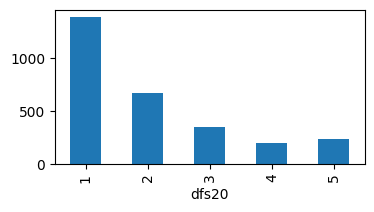

In [9]:
plt.figure(figsize=(4, 2)) # width, height in inches
y20_train.value_counts().sort_index().plot(kind='bar')
plt.show()

---

## Logistic Regression  
Check if LR gets a reasonable kappa (> 0.3).  

In [10]:
lr20_model = LogisticRegression (
    C=np.float64(0.0019145111285710716),
    solver='saga',
    random_state=42
)

In [11]:
lr20_model.fit(X20_train, y20_train)

,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",np.float64(0....5111285710716)
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'saga'
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_r

In [12]:
lr20_y_pred = lr20_model.predict(X20_test)

### classification report

In [13]:
print(classification_report(y20_test, lr20_y_pred))

              precision    recall  f1-score   support

           1       0.76      0.93      0.84       684
           2       0.45      0.42      0.43       331
           3       0.40      0.26      0.31       174
           4       0.30      0.03      0.05       100
           5       0.57      0.68      0.62       114

    accuracy                           0.64      1403
   macro avg       0.50      0.46      0.45      1403
weighted avg       0.59      0.64      0.60      1403



In [14]:
print(f"Exact accuracy:        {accuracy_score(y20_test, lr20_y_pred):.2f}")
print(f"Macro F1:              {f1_score(y20_test, lr20_y_pred, average='macro', zero_division=0):.2f}")
print(f"Weighted F1:           {f1_score(y20_test, lr20_y_pred, average='weighted', zero_division=0):.2f}")
print(f"Micro F1:              {f1_score(y20_test, lr20_y_pred, average='micro'):.2f}")
print(f"Within ±1 accuracy:    {np.mean(np.abs(np.asarray(y20_test) - np.asarray(lr20_y_pred)) <= 1):.2f}")
print(f"Quadratic weighted κ:  {cohen_kappa_score(y20_test, lr20_y_pred, weights='quadratic'):.2f}")

Exact accuracy:        0.64
Macro F1:              0.45
Weighted F1:           0.60
Micro F1:              0.64
Within ±1 accuracy:    0.93
Quadratic weighted κ:  0.80


---

## LogisticAT

```
Best LRAT balanced_accuracy score: 0.6116116009203096  
Best LRAT params: {'alpha': np.float64(55.51721685244721), 'max_iter': 5000}
```

In [15]:
lrat20_model = LogisticAT(
    alpha=np.float64(55.51721685244721),
    max_iter=5000,
).fit(X20_train, y20_train)

In [16]:
lrat20_y_pred = lrat20_model.predict(X20_test)

### classification report

In [17]:
print(classification_report(y20_test, lrat20_y_pred))

              precision    recall  f1-score   support

           1       0.83      0.88      0.85       684
           2       0.52      0.53      0.53       331
           3       0.44      0.38      0.41       174
           4       0.35      0.36      0.35       100
           5       0.72      0.54      0.62       114

    accuracy                           0.67      1403
   macro avg       0.57      0.54      0.55      1403
weighted avg       0.66      0.67      0.67      1403



In [18]:
print(f"Exact accuracy:        {accuracy_score(y20_test, lrat20_y_pred):.2f}")
print(f"Macro F1:              {f1_score(y20_test, lrat20_y_pred, average='macro', zero_division=0):.2f}")
print(f"Weighted F1:           {f1_score(y20_test, lrat20_y_pred, average='weighted', zero_division=0):.2f}")
print(f"Micro F1:              {f1_score(y20_test, lrat20_y_pred, average='micro'):.2f}")
print(f"Within ±1 accuracy:    {np.mean(np.abs(np.asarray(y20_test) - np.asarray(lrat20_y_pred)) <= 1):.2f}")
print(f"Quadratic weighted κ:  {cohen_kappa_score(y20_test, lrat20_y_pred, weights='quadratic'):.2f}")

Exact accuracy:        0.67
Macro F1:              0.55
Weighted F1:           0.67
Micro F1:              0.67
Within ±1 accuracy:    0.97
Quadratic weighted κ:  0.85


---

## XGBoost

In [19]:
# # XGBoost requires class labels to be the consecutive integers 0 to K−1, and the other models don't. 
# # If you'd rather keep y as 1–5 for everything else, shift the labels for XGBoost alone:
y20_train_xgb = y20_train - 1
y20_test_xgb = y20_test - 1

In [20]:
xgb20_params = { 
    'colsample_bytree': np.float64(0.8512420419935547),
    'gamma': np.float64(0.02136716900898964),
    'learning_rate': np.float64(0.014768002316749563),
    'max_depth': 3,
    'min_child_weight': np.float64(9.927051213197453),
    'n_estimators': 507,
    'reg_alpha': np.float64(4.497407193749844),
    'reg_lambda': np.float64(0.11101191524846071),
    'subsample': np.float64(0.8006065178748798),
    'objective': 'multi:softprob',
    'eval_metric': 'mlogloss',
    'tree_method': 'hist',
    'random_state': 42,
    'n_jobs': 1, 
}

xgb20_model = xgb.XGBClassifier(
        **xgb20_params,
).fit(X20_train, y20_train_xgb)

In [21]:
# Shift the predictions back so they're on the same 1–5 scale as the other models.
xgb20_y_pred = xgb20_model.predict(X20_test) + 1
xgb20_labels = np.unique(np.concatenate([np.asarray(y20_test), xgb20_y_pred]))

## classification report

In [22]:
print(classification_report(y20_test, xgb20_y_pred, labels=xgb20_labels))

              precision    recall  f1-score   support

           1       0.82      0.89      0.86       684
           2       0.55      0.54      0.54       331
           3       0.43      0.36      0.39       174
           4       0.45      0.37      0.41       100
           5       0.68      0.61      0.65       114

    accuracy                           0.68      1403
   macro avg       0.59      0.56      0.57      1403
weighted avg       0.67      0.68      0.68      1403



In [23]:
print(f"Exact accuracy:        {accuracy_score(y20_test, xgb20_y_pred):.2f}")
print(f"Macro F1:              {f1_score(y20_test, xgb20_y_pred, average='macro', zero_division=0):.2f}")
print(f"Weighted F1:           {f1_score(y20_test, xgb20_y_pred, average='weighted', zero_division=0):.2f}")
print(f"Micro F1:              {f1_score(y20_test, xgb20_y_pred, average='micro'):.2f}")
print(f"Within ±1 accuracy:    {np.mean(np.abs(np.asarray(y20_test) - np.asarray(xgb20_y_pred)) <= 1):.2f}")
print(f"Quadratic weighted κ:  {cohen_kappa_score(y20_test, xgb20_y_pred, weights='quadratic'):.2f}")

Exact accuracy:        0.68
Macro F1:              0.57
Weighted F1:           0.68
Micro F1:              0.68
Within ±1 accuracy:    0.95
Quadratic weighted κ:  0.83


---

## Catboost

In [24]:
cbc20_params = {
    'auto_class_weights': 'SqrtBalanced',  
    'bagging_temperature': np.float64(0.770967179954561),  
    'border_count': 128,  
    'depth': 5,  
    'iterations': 592,  
    'l2_leaf_reg': np.float64(11.213346937437466),  
    'learning_rate': np.float64(0.013940305267157801),  
    'random_strength': np.float64(0.8786730037315402)
}
cbc20_model = CatBoostClassifier(**cbc20_params).fit(X20_train, y20_train, verbose=0)

In [25]:
cbc20_y_pred = cbc20_model.predict(X20_test)

In [26]:
print(classification_report(y20_test, cbc20_y_pred))

              precision    recall  f1-score   support

           1       0.87      0.84      0.85       684
           2       0.54      0.58      0.56       331
           3       0.45      0.48      0.46       174
           4       0.38      0.40      0.39       100
           5       0.72      0.59      0.65       114

    accuracy                           0.68      1403
   macro avg       0.59      0.58      0.58      1403
weighted avg       0.69      0.68      0.69      1403



In [27]:
print(f"Exact accuracy:        {accuracy_score(y20_test, cbc20_y_pred):.2f}")
print(f"Macro F1:              {f1_score(y20_test, cbc20_y_pred, average='macro', zero_division=0):.2f}")
print(f"Weighted F1:           {f1_score(y20_test, cbc20_y_pred, average='weighted', zero_division=0):.2f}")
print(f"Micro F1:              {f1_score(y20_test, cbc20_y_pred, average='micro'):.2f}")
print(f"Within ±1 accuracy:    {np.mean(np.abs(np.asarray(y20_test) - np.asarray(cbc20_y_pred)) <= 1):.2f}")
print(f"Quadratic weighted κ:  {cohen_kappa_score(y20_test, cbc20_y_pred, weights='quadratic'):.2f}")

Exact accuracy:        0.68
Macro F1:              0.58
Weighted F1:           0.69
Micro F1:              0.68
Within ±1 accuracy:    0.65
Quadratic weighted κ:  0.85


---

## Score Summary

In [28]:
print("Exact accuracy: \n",
    f"       LR: {accuracy_score(y20_test, lr20_y_pred):.2f}",
    f"       LRAT: {accuracy_score(y20_test, lrat20_y_pred):.2f}",
    f"       XGB: {accuracy_score(y20_test, xgb20_y_pred):.2f}",
    f"       CBC: {accuracy_score(y20_test, cbc20_y_pred):.2f}"
)
print("Macro F1: \n",
    f"       LR: {f1_score(y20_test, lr20_y_pred, average='macro', zero_division=0):.2f}",
    f"       LRAT: {f1_score(y20_test, lrat20_y_pred, average='macro', zero_division=0):.2f}",
    f"       XGB: {f1_score(y20_test, xgb20_y_pred, average='macro', zero_division=0):.2f}",
    f"       CBC: {f1_score(y20_test, cbc20_y_pred, average='macro', zero_division=0):.2f}"
)
print("Weighted F1: \n",
    f"       LR: {f1_score(y20_test, lr20_y_pred, average='weighted', zero_division=0):.2f}",
    f"       LRAT: {f1_score(y20_test, lrat20_y_pred, average='weighted', zero_division=0):.2f}",
    f"       XGB: {f1_score(y20_test, xgb20_y_pred, average='weighted', zero_division=0):.2f}",
    f"       CBC: {f1_score(y20_test, cbc20_y_pred, average='weighted', zero_division=0):.2f}"
)
print("Macro F1: \n",
    f"       LR: {f1_score(y20_test, lr20_y_pred, average='micro', zero_division=0):.2f}",
    f"       LRAT: {f1_score(y20_test, lrat20_y_pred, average='micro', zero_division=0):.2f}",
    f"       XGB: {f1_score(y20_test, xgb20_y_pred, average='micro', zero_division=0):.2f}",
    f"       CBC: {f1_score(y20_test, cbc20_y_pred, average='micro', zero_division=0):.2f}"
)
print("Within ±1 accuracy: \n",
    f"       LR: {np.mean(np.abs(np.asarray(y20_test) - np.asarray(lrat20_y_pred)) <= 1):.2f}",
    f"       LRAT: {np.mean(np.abs(np.asarray(y20_test) - np.asarray(lrat20_y_pred)) <= 1):.2f}",
    f"       XGB: {np.mean(np.abs(np.asarray(y20_test) - np.asarray(xgb20_y_pred)) <= 1):.2f}",
    f"       CBC: {np.mean(np.abs(np.asarray(y20_test) - np.asarray(cbc20_y_pred)) <= 1):.2f}"
)
print("Quadratic weighted κ: \n",
    f"       LR: {cohen_kappa_score(y20_test, lr20_y_pred, weights='quadratic'):.2f}",
    f"       LRAT: {cohen_kappa_score(y20_test, lrat20_y_pred, weights='quadratic'):.2f}",
    f"       XGB: {cohen_kappa_score(y20_test, xgb20_y_pred, weights='quadratic'):.2f}",
    f"       CBC: {cohen_kappa_score(y20_test, cbc20_y_pred, weights='quadratic'):.2f}"
)

Exact accuracy: 
        LR: 0.64        LRAT: 0.67        XGB: 0.68        CBC: 0.68
Macro F1: 
        LR: 0.45        LRAT: 0.55        XGB: 0.57        CBC: 0.58
Weighted F1: 
        LR: 0.60        LRAT: 0.67        XGB: 0.68        CBC: 0.69
Macro F1: 
        LR: 0.64        LRAT: 0.67        XGB: 0.68        CBC: 0.68
Within ±1 accuracy: 
        LR: 0.97        LRAT: 0.97        XGB: 0.95        CBC: 0.65
Quadratic weighted κ: 
        LR: 0.80        LRAT: 0.85        XGB: 0.83        CBC: 0.85


---

## Stacking Classifer

In [99]:
# estimators20 = [
#     ('lr20', lr20_model),
#     # ('lrat20', lrat20_model),
#     ('xgb20', xgb20_model),
#     # ('cbc20', cbc20_model)
# ]

In [135]:
estimators20 = [
    ('lr20', lr20_model),
    # ('lrat20', lrat20_model),
    ('xgb20', xgb20_model),
    # ('cbc20', cbc20_model)
]
stack20_model = StackingClassifier(
    estimators=estimators20,
    final_estimator=LogisticRegression(C=1.0, max_iter=2000),
    stack_method="predict_proba",
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    passthrough=False,
    verbose=0,
    n_jobs=1,   # CatBoost/XGBoost manage their own threads
).fit(X20_train, y20_train)
stack20_y_pred = stack20_model.predict(X20_test)
print(classification_report(y20_test, stack20_y_pred))

              precision    recall  f1-score   support

           1       0.84      0.88      0.86       684
           2       0.55      0.56      0.55       331
           3       0.43      0.42      0.43       174
           4       0.45      0.37      0.41       100
           5       0.72      0.63      0.67       114

    accuracy                           0.69      1403
   macro avg       0.60      0.57      0.58      1403
weighted avg       0.68      0.69      0.69      1403



In [101]:
# stack20_y_pred = stack20.predict(X20_test)

In [117]:
# print(classification_report(y20_test, stack20_y_pred))

In [90]:
print(f"Exact accuracy:        {accuracy_score(y20_test, stack20_y_pred):.2f}")
print(f"Macro F1:              {f1_score(y20_test, stack20_y_pred, average='macro', zero_division=0):.2f}")
print(f"Weighted F1:           {f1_score(y20_test, stack20_y_pred, average='weighted', zero_division=0):.2f}")
print(f"Micro F1:              {f1_score(y20_test, stack20_y_pred, average='micro'):.2f}")
print(f"Within ±1 accuracy:    {np.mean(np.abs(np.asarray(y20_test) - np.asarray(stack20_y_pred)) <= 1):.2f}")
print(f"Quadratic weighted κ:  {cohen_kappa_score(y20_test, stack20_y_pred, weights='quadratic'):.2f}")

Exact accuracy:        0.69
Macro F1:              0.58
Weighted F1:           0.69
Micro F1:              0.69
Within ±1 accuracy:    0.96
Quadratic weighted κ:  0.85


In [103]:
# estimators_base = [
#     ('lr', LogisticRegression(random_state=42)),
#     ('lrat', LogisticAT()),
#     ('xgb', xgb.XGBClassifier(random_state=42)),
#     ('cbc', CatBoostClassifier(random_state=42))
# ]

In [140]:
estimators_base = [
    ('lr', LogisticRegression(random_state=42)),
    # ('lrat', LogisticAT()),
    ('xgb', xgb.XGBClassifier(random_state=42)),
    # ('cbc', CatBoostClassifier(random_state=42))
]
stack_base_model = StackingClassifier(
    estimators=estimators_base,
    final_estimator=LogisticRegression(C=1.0, max_iter=2000),
    stack_method="predict_proba",
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    passthrough=False,
    verbose=0,
    n_jobs=1,   # CatBoost/XGBoost manage their own threads
).fit(X20_train, y20_train)
stack_base_y_pred = stack_base_model.predict(X20_test)
print(classification_report(y20_test, stack_base_y_pred))

              precision    recall  f1-score   support

           1       0.83      0.89      0.86       684
           2       0.55      0.53      0.54       331
           3       0.45      0.41      0.43       174
           4       0.37      0.31      0.34       100
           5       0.65      0.58      0.61       114

    accuracy                           0.68      1403
   macro avg       0.57      0.55      0.56      1403
weighted avg       0.67      0.68      0.67      1403



In [141]:
# stack_base_y_pred = stack_base_model.predict(X20_test)

In [142]:
# print(classification_report(y20_test, stack_base_y_pred))

In [144]:
print("Exact accuracy: \n",
    f"       LR: {accuracy_score(y20_test, lr20_y_pred):.2f}",
    f"       LRAT: {accuracy_score(y20_test, lrat20_y_pred):.2f}",
    f"       XGB: {accuracy_score(y20_test, xgb20_y_pred):.2f}",
    f"       CBC: {accuracy_score(y20_test, cbc20_y_pred):.2f}",
    f"       Stack 20: {accuracy_score(y20_test, stack20_y_pred):.2f}",
    f"       Stack Base: {accuracy_score(y20_test, stack_base_y_pred):.2f}"
)
print("Macro F1: \n",
    f"       LR: {f1_score(y20_test, lr20_y_pred, average='macro', zero_division=0):.2f}",
    f"       LRAT: {f1_score(y20_test, lrat20_y_pred, average='macro', zero_division=0):.2f}",
    f"       XGB: {f1_score(y20_test, xgb20_y_pred, average='macro', zero_division=0):.2f}",
    f"       CBC: {f1_score(y20_test, cbc20_y_pred, average='macro', zero_division=0):.2f}",
    f"       Stack 20: {f1_score(y20_test, stack20_y_pred, average='macro', zero_division=0):.2f}",
    f"       Stack Base: {f1_score(y20_test, stack_base_y_pred, average='macro', zero_division=0):.2f}"
)
print("Weighted F1: \n",
    f"       LR: {f1_score(y20_test, lr20_y_pred, average='weighted', zero_division=0):.2f}",
    f"       LRAT: {f1_score(y20_test, lrat20_y_pred, average='weighted', zero_division=0):.2f}",
    f"       XGB: {f1_score(y20_test, xgb20_y_pred, average='weighted', zero_division=0):.2f}",
    f"       CBC: {f1_score(y20_test, cbc20_y_pred, average='weighted', zero_division=0):.2f}",
    f"       Stack 20: {f1_score(y20_test, stack20_y_pred, average='weighted', zero_division=0):.2f}",
    f"       Stack Base: {f1_score(y20_test, stack_base_y_pred, average='weighted', zero_division=0):.2f}",
)
print("Macro F1: \n",
    f"       LR: {f1_score(y20_test, lr20_y_pred, average='micro', zero_division=0):.2f}",
    f"       LRAT: {f1_score(y20_test, lrat20_y_pred, average='micro', zero_division=0):.2f}",
    f"       XGB: {f1_score(y20_test, xgb20_y_pred, average='micro', zero_division=0):.2f}",
    f"       CBC: {f1_score(y20_test, cbc20_y_pred, average='micro', zero_division=0):.2f}",
    f"       Stack 20: {f1_score(y20_test, stack20_y_pred, average='micro', zero_division=0):.2f}",
    f"       Stack Base: {f1_score(y20_test, stack_base_y_pred, average='micro', zero_division=0):.2f}"
)
print("Within ±1 accuracy: \n",
    f"       LR: {np.mean(np.abs(np.asarray(y20_test) - np.asarray(lrat20_y_pred)) <= 1):.2f}",
    f"       LRAT: {np.mean(np.abs(np.asarray(y20_test) - np.asarray(lrat20_y_pred)) <= 1):.2f}",
    f"       XGB: {np.mean(np.abs(np.asarray(y20_test) - np.asarray(xgb20_y_pred)) <= 1):.2f}",
    f"       CBC: {np.mean(np.abs(np.asarray(y20_test) - np.asarray(cbc20_y_pred)) <= 1):.2f}",
    f"       Stack 20: {np.mean(np.abs(np.asarray(y20_test) - np.asarray(stack20_y_pred)) <= 1):.2f}",
    f"       Stack Base: {np.mean(np.abs(np.asarray(y20_test) - np.asarray(stack_base_y_pred)) <= 1):.2f}"
)
print("Quadratic weighted κ: \n",
    f"       LR: {cohen_kappa_score(y20_test, lr20_y_pred, weights='quadratic'):.2f}",
    f"       LRAT: {cohen_kappa_score(y20_test, lrat20_y_pred, weights='quadratic'):.2f}",
    f"       XGB: {cohen_kappa_score(y20_test, xgb20_y_pred, weights='quadratic'):.2f}",
    f"       CBC: {cohen_kappa_score(y20_test, cbc20_y_pred, weights='quadratic'):.2f}",
    f"       Stack 20: {cohen_kappa_score(y20_test, stack20_y_pred, weights='quadratic'):.2f}",
    f"       Stack Base: {cohen_kappa_score(y20_test, stack_base_y_pred, weights='quadratic'):.2f}"
)

Exact accuracy: 
        LR: 0.64        LRAT: 0.67        XGB: 0.68        CBC: 0.68        Stack 20: 0.69        Stack Base: 0.68
Macro F1: 
        LR: 0.45        LRAT: 0.55        XGB: 0.57        CBC: 0.58        Stack 20: 0.58        Stack Base: 0.56
Weighted F1: 
        LR: 0.60        LRAT: 0.67        XGB: 0.68        CBC: 0.69        Stack 20: 0.69        Stack Base: 0.67
Macro F1: 
        LR: 0.64        LRAT: 0.67        XGB: 0.68        CBC: 0.68        Stack 20: 0.69        Stack Base: 0.68
Within ±1 accuracy: 
        LR: 0.97        LRAT: 0.97        XGB: 0.95        CBC: 0.65        Stack 20: 0.96        Stack Base: 0.96
Quadratic weighted κ: 
        LR: 0.80        LRAT: 0.85        XGB: 0.83        CBC: 0.85        Stack 20: 0.85        Stack Base: 0.85
